In [42]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

import warnings
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.neighbors import KNeighborsRegressor


warnings.filterwarnings('ignore')

In [25]:
df = pd.read_csv("12-house_energy_regression.csv")

In [26]:
df.head()

,avg_indoor_temp_change,outdoor_humidity_level,daily_energy_consumption_kwh
0,-0.167118,0.146714,-14.996950
1,-0.020902,0.117327,-12.678089
2,0.150419,0.364961,17.775455
3,0.555604,0.089581,6.661465
4,0.058209,-1.142970,-14.195530


In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   avg_indoor_temp_change        1000 non-null   float64
 1   outdoor_humidity_level        1000 non-null   float64
 2   daily_energy_consumption_kwh  1000 non-null   float64
dtypes: float64(3)
memory usage: 23.6 KB


In [28]:
df.describe()

,avg_indoor_temp_change,outdoor_humidity_level,daily_energy_consumption_kwh
count,1000.000000,1000.000000,1000.000000
mean,0.033186,0.056982,1.766025
std,0.961603,1.014959,41.299085
min,-3.241267,-2.940389,-132.797922
25%,-0.611581,-0.651418,-25.600072
50%,0.036043,0.047742,1.065474
75%,0.648317,0.714886,28.766573
max,3.078881,3.852731,138.577662


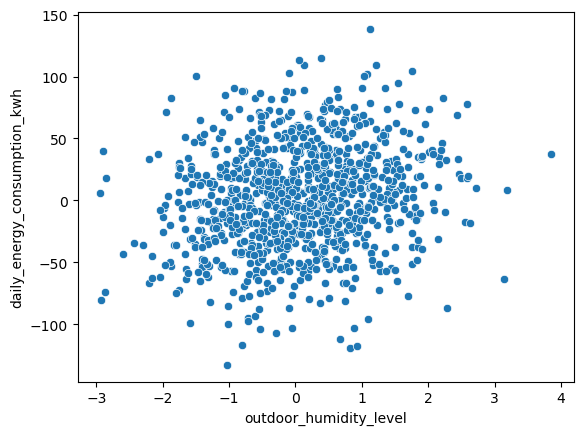

In [39]:
sns.scatterplot(x=df["outdoor_humidity_level"], y=df["daily_energy_consumption_kwh"])
plt.show()

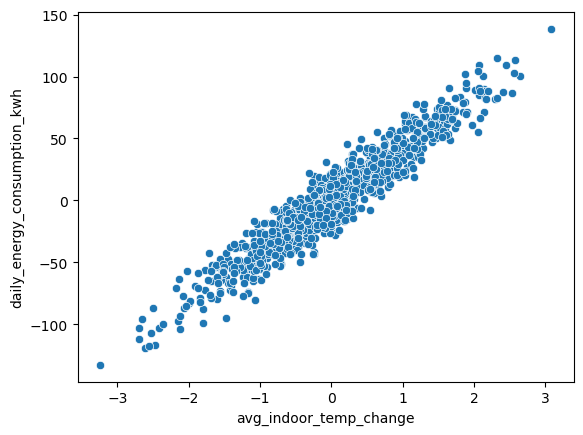

In [40]:
sns.scatterplot(x=df["avg_indoor_temp_change"], y=df["daily_energy_consumption_kwh"])
plt.show()

In [34]:
X = df.drop("daily_energy_consumption_kwh", axis=1)
y = df["daily_energy_consumption_kwh"]

In [35]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.25, random_state=15)

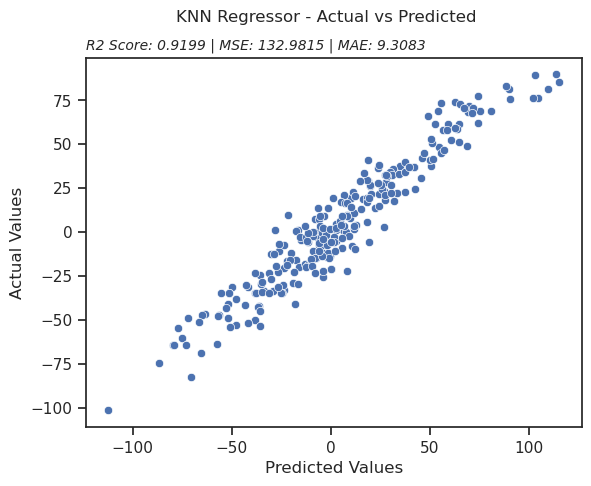

In [62]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knr", KNeighborsRegressor(n_neighbors=6))
])
   
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

sns.set_theme(style=("ticks"))
sns.scatterplot(
    x = y_test,
    y = y_pred
)
plt.suptitle("KNN Regressor - Actual vs Predicted",fontsize = 12)

plt.title(f'R2 Score: {r2:.4f} | MSE: {mse:.4f} | MAE: {mae:.4f}', fontsize=10, loc='left', style='italic')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.show()